In [84]:
import numpy as np
import pandas as pd
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import subjectivity
from nltk.sentiment import SentimentAnalyzer
from nltk.sentiment.util import *

import numpy as np 
import pandas as pd 
#pd.set_option('display.max_colwidth', -1)
from time import time
import re
import string
import os
#import emoji
from pprint import pprint
import collections

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")
sns.set(font_scale=1.3)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
#from sklearn.externals import joblib
import joblib as jb

#import gensim

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import warnings
warnings.filterwarnings('ignore')

np.random.seed(37)

# import stata_setup
# stata_setup.config('C:/Users/Farid Srouji/OneDrive/Stata15/', 'mp')
# import sys
# sys.path.append("C:/Users/Farid Srouji/OneDrive/Stata15/utilities")
# from pystata import config
# config.init()

In [85]:
import ipystata  

In [86]:
%%stata  
display "Hello, I am printed in Stata." 
describe


Hello, I am printed in Stata.

Contains data
  obs:             0                          
 vars:             0                          
 size:             0                          
Sorted by: 


In [87]:
%%stata 
scatter mpg price


variable mpg not found
r(111);

end of do-file
r(111);


In [88]:
%%stata
sysuse sp500, clear
graph twoway line high low date


(S&P 500)


In [89]:
# Reading the saved data pickle file
df_vix = pd.read_pickle('/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/data/pkl/pickled_one_year_filtered_lead_para_sp500_clean.pkl')

In [90]:
%%stata
sysuse sp500, clear

#graph twoway line close date


(S&P 500)
Unknown #command


In [91]:
df_vix

,close,adj close,articles
2011-01-04,17.379999,17.379999,. A Push to Privatize Pennsylvania Liquor Stor...
2011-01-05,17.020000,17.020000,. A Turnaround for Anadarko. Don’t Call It a C...
2011-01-06,17.400000,17.400000,". Health Spending Rose in ’09, but at Low Rate..."
2011-01-07,17.139999,17.139999,. MBIA Fights Banks for Its Life. Obama Plan A...
2011-01-08,17.273333,17.273333,. Flex Time Flourishes in Accounting Industry....
...,...,...,...
2021-05-28,16.760000,16.760000,. Coast Guard Search Fails to Locate 10 Cuban ...
2021-05-29,17.045000,17.045000,. Anniversary Event for Tulsa Race Massacre Un...
2021-05-30,17.330000,17.330000,. A Nashville hat store sold ‘Not Vaccinated’ ...
2021-05-31,17.615000,17.615000,The Internet’s Favorite Catalog of Weird Place...


In [92]:
#df_vix.columns = ['date', 'close', 'adj close', 'articles']
#df_vix[['date', 'close']] = df_vix['close'].split(' ', 1, expand=True)
#df_vix = pd.DataFrame(df_vix.close.first.split(' ',1).tolist(),
                                 #columns = ['date','close'])
#print(df_vix.close. to_string().split(' ',1))
#df_new = pd.DataFrame(df_vix.close.to_string().split(' ',1), columns = ['date','close'])
#print(type(df_vix.close.to_list().))
df_vix
#df_vix = pd.DataFrame(df_vix.close.to_string().split(' ',1), columns = ['date','close'])

,close,adj close,articles
2011-01-04,17.379999,17.379999,. A Push to Privatize Pennsylvania Liquor Stor...
2011-01-05,17.020000,17.020000,. A Turnaround for Anadarko. Don’t Call It a C...
2011-01-06,17.400000,17.400000,". Health Spending Rose in ’09, but at Low Rate..."
2011-01-07,17.139999,17.139999,. MBIA Fights Banks for Its Life. Obama Plan A...
2011-01-08,17.273333,17.273333,. Flex Time Flourishes in Accounting Industry....
...,...,...,...
2021-05-28,16.760000,16.760000,. Coast Guard Search Fails to Locate 10 Cuban ...
2021-05-29,17.045000,17.045000,. Anniversary Event for Tulsa Race Massacre Un...
2021-05-30,17.330000,17.330000,. A Nashville hat store sold ‘Not Vaccinated’ ...
2021-05-31,17.615000,17.615000,The Internet’s Favorite Catalog of Weird Place...


In [93]:
#df_vix.reset_index(level=0, inplace=True)
df_vix['VIX'] = df_vix['adj close'].apply(np.int)

#df_vix['date'] = df_vix.index

In [94]:
df_vix#from pandas import DataFrame

#df1 = DataFrame(df_vix[df_vix.columns[0]].to_string().split(" ",569), columns=['date'])
# ts=pd.Series(df_vix[df_vix.columns[0]], index=pd.date_range("25/09/2019", periods=569))
# ts.plot()

,close,adj close,articles,VIX
2011-01-04,17.379999,17.379999,. A Push to Privatize Pennsylvania Liquor Stor...,17
2011-01-05,17.020000,17.020000,. A Turnaround for Anadarko. Don’t Call It a C...,17
2011-01-06,17.400000,17.400000,". Health Spending Rose in ’09, but at Low Rate...",17
2011-01-07,17.139999,17.139999,. MBIA Fights Banks for Its Life. Obama Plan A...,17
2011-01-08,17.273333,17.273333,. Flex Time Flourishes in Accounting Industry....,17
...,...,...,...,...
2021-05-28,16.760000,16.760000,. Coast Guard Search Fails to Locate 10 Cuban ...,16
2021-05-29,17.045000,17.045000,. Anniversary Event for Tulsa Race Massacre Un...,17
2021-05-30,17.330000,17.330000,. A Nashville hat store sold ‘Not Vaccinated’ ...,17
2021-05-31,17.615000,17.615000,The Internet’s Favorite Catalog of Weird Place...,17


In [95]:
#df_vix = df_vix.reset_index()

In [96]:
#df_vix['index']

In [97]:
#df_vix = df_vix.reset_index()
# df_vix['adj close'] = df_vix['adj close'].apply(np.float64) + 0.5
#df_vix['VIX'] = df_vix['adj close']
df_vix.columns.values[1] = "VIX"
#decimals = 2
#df_vix['VIX'] = df_vix['adj close'].apple(np.round)
#df_vix['text'] = df_vix['articles'].str()

In [98]:
df_vix

,close,VIX,articles,VIX
2011-01-04,17.379999,17.379999,. A Push to Privatize Pennsylvania Liquor Stor...,17
2011-01-05,17.020000,17.020000,. A Turnaround for Anadarko. Don’t Call It a C...,17
2011-01-06,17.400000,17.400000,". Health Spending Rose in ’09, but at Low Rate...",17
2011-01-07,17.139999,17.139999,. MBIA Fights Banks for Its Life. Obama Plan A...,17
2011-01-08,17.273333,17.273333,. Flex Time Flourishes in Accounting Industry....,17
...,...,...,...,...
2021-05-28,16.760000,16.760000,. Coast Guard Search Fails to Locate 10 Cuban ...,16
2021-05-29,17.045000,17.045000,. Anniversary Event for Tulsa Race Massacre Un...,17
2021-05-30,17.330000,17.330000,. A Nashville hat store sold ‘Not Vaccinated’ ...,17
2021-05-31,17.615000,17.615000,The Internet’s Favorite Catalog of Weird Place...,17


In [99]:
# selecting the VIX and articles
df_vix = df_vix[['VIX', 'articles']]

In [100]:
#df_vix['articles'] = df_vix['articles'].map(lambda x: x.lstrip('.-'))

In [101]:
df_vix

,VIX,articles
2011-01-04,17,. A Push to Privatize Pennsylvania Liquor Stor...
2011-01-05,17,. A Turnaround for Anadarko. Don’t Call It a C...
2011-01-06,17,". Health Spending Rose in ’09, but at Low Rate..."
2011-01-07,17,. MBIA Fights Banks for Its Life. Obama Plan A...
2011-01-08,17,. Flex Time Flourishes in Accounting Industry....
...,...,...
2021-05-28,16,. Coast Guard Search Fails to Locate 10 Cuban ...
2021-05-29,17,. Anniversary Event for Tulsa Race Massacre Un...
2021-05-30,17,. A Nashville hat store sold ‘Not Vaccinated’ ...
2021-05-31,17,The Internet’s Favorite Catalog of Weird Place...


In [102]:
df = df_vix[['VIX']].copy()
df


,VIX
2011-01-04,17
2011-01-05,17
2011-01-06,17
2011-01-07,17
2011-01-08,17
...,...
2021-05-28,16
2021-05-29,17
2021-05-30,17
2021-05-31,17


In [103]:
df_vix = df_vix.reindex(np.random.permutation(df_vix.index))  
df_vix = df_vix[['VIX', 'articles']]

In [104]:
# Adding new columns to the data frame
df['compound'] = ''
df['neg'] = ''
df['neu'] = ''
df['pos'] = ''

In [105]:
df

,VIX,compound,neg,neu,pos
2011-01-04,17,,,,
2011-01-05,17,,,,
2011-01-06,17,,,,
2011-01-07,17,,,,
2011-01-08,17,,,,
...,...,...,...,...,...
2021-05-28,16,,,,
2021-05-29,17,,,,
2021-05-30,17,,,,
2021-05-31,17,,,,


In [106]:
#import nltk
#nltk.download('vader_lexicon')

In [107]:
import nltk
nltk.download('vader_lexicon')
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import unicodedata
sid = SentimentIntensityAnalyzer()
countNeg=0
countNeu=0
countPos=0
#print(df_vix['articles'])
for date, row in df_vix.T.iteritems():
    print("The date is:"+str(date))
    try:
        sentence = unicodedata.normalize('NFKD', df_vix.loc[date, 'articles'])#.encode('ascii','ignore').decode('ascii')
        #sentence = unicodedata.normalize('NFKD', df_vix.loc[date, 'articles']).encode('ascii','ignore')
        # add my own sentence Options sentiment.
        #print("#1")
        #print (df_vix.loc[date, 'articles'])
        ss = sid.polarity_scores(sentence)
        #print(sentence)
        #print("#2")
        df.at[date, 'compound'] = ss['compound']
        df.at[date, 'neg'] = ss['neg']
        df.at[date, 'neu'] = ss['neu']
        df.at[date, 'pos'] = ss['pos']
        if ((ss['pos'] + ss['neg']) != 0):
            df.at[date, 'ForGraph'] = 100*(ss['pos'] / (ss['pos'] + ss['neg']))
        countNeg+=ss['neg']
        countNeu+=ss['neu']
        countPos+=ss['pos']
        
        print("============sentiment status============")
        print("compound="+str(df.at[date, 'compound']))
        print("neg="+str(df.at[date, 'neg']))
        print("neu="+str(df.at[date, 'neu']))
        print("pos="+str(df.at[date, 'pos']))
        print("ForGraph="+str(df.at[date, 'ForGraph']))
        #print("passed")
    except TypeError:
        #print("sentence is")
        #print(sentence)
        #print(df_vix.loc[date, 'articles'])
        print("ERROR")
        df.at[date, 'compound'] = 0
        df.at[date, 'neg'] = 0
        df.at[date, 'neu'] = 0
        df.at[date, 'pos'] = 0
#df.diff().hist(color="k", alpha=0.5, bins=50);



compound=-0.9612
neg=0.121
neu=0.786
pos=0.093
ForGraph=43.45794392523364
The date is:2015-07-17 00:00:00
============sentiment status============
compound=-0.9882
neg=0.129
neu=0.782
pos=0.089
ForGraph=40.825688073394495
The date is:2017-10-10 00:00:00
============sentiment status============
compound=-0.9978
neg=0.178
neu=0.732
pos=0.089
ForGraph=33.33333333333333
The date is:2016-06-14 00:00:00
============sentiment status============
compound=-0.9983
neg=0.167
neu=0.783
pos=0.05
ForGraph=23.04147465437788
The date is:2015-03-31 00:00:00
============sentiment status============
compound=-0.9998
neg=0.166
neu=0.771
pos=0.063
ForGraph=27.510917030567683
The date is:2015-09-25 00:00:00
============sentiment status============
compound=-0.8403
neg=0.115
neu=0.782
pos=0.103
ForGraph=47.24770642201835
The date is:2013-04-04 00:00:00
============sentiment status============
compound=-0.972
neg=0.124
neu=0.777
pos=0.099
ForGraph=44.39461883408072
The date is:2015-01-26 00:00:00
============

In [108]:
df

,VIX,compound,neg,neu,pos,ForGraph
2011-01-04,17,-0.9992,0.18,0.71,0.109,37.716263
2011-01-05,17,-0.9925,0.183,0.731,0.086,31.970260
2011-01-06,17,-0.9956,0.211,0.711,0.078,26.989619
2011-01-07,17,-0.989,0.162,0.722,0.115,41.516245
2011-01-08,17,-0.9963,0.199,0.684,0.117,37.025316
...,...,...,...,...,...,...
2021-05-28,16,-0.9275,0.109,0.8,0.092,45.771144
2021-05-29,17,-0.9897,0.142,0.81,0.048,25.263158
2021-05-30,17,-0.9934,0.166,0.804,0.03,15.306122
2021-05-31,17,-0.5139,0.104,0.795,0.1,49.019608


In [109]:
# df.to_csv(r'/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/data/stata/sentiment.csv', index = False)
# df.to_csv(r'/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/data/stata/sentiment.csv', index = False)


Total Neg=566.2829999999999 | Total Neu=2899.224999999999 | Total Pos=335.51800000000094


<AxesSubplot:title={'center':'sentiment by date'}>

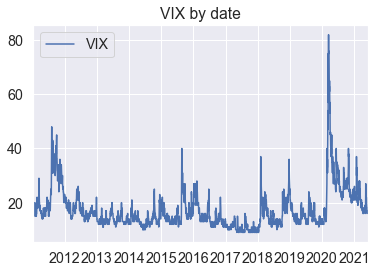

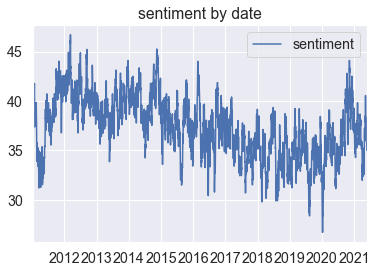

In [110]:
#plt.figure();
#df['sentiment'] = df['ForGraph']#.ewm(span=20).mean()
#print(df.values)
#senDF = df.values
#senDF.all.hist(color="k", alpha=0.5, bins=50);

print("Total Neg="+str(countNeg)+" | Total Neu="+str(countNeu)+" | Total Pos="+str(countPos))

#df = pd.Series(data=df, index=pd.date_range("09/25/2019", periods=569))
df['sentiment'] = df['ForGraph'].ewm(span=20).mean()
# ts=pd.Series(df['sentiment'], index=pd.date_range("25/09/2019", periods=569))
# ts.plot()
df[['VIX']].plot(title='VIX by date')
#df[['ForGraph']].plot(title='sentiment by date')
df[['sentiment']].plot(title='sentiment by date')

#sns.boxplot(x='diagnosis', y='area_mean', data=df)
#df.at[date, 'pos'].plot(title='Sentiment by date')
# ts=pd.Series(df['VIX'])#, index=pd.date_range("25/09/2019", periods=569))
# ts.plot()
# df_vix.diff().hist(color="k", alpha=0.5, bins=50);
# ts.plot()
#predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=20).mean()


In [111]:
df

,VIX,compound,neg,neu,pos,ForGraph,sentiment
2011-01-04,17,-0.9992,0.18,0.71,0.109,37.716263,37.716263
2011-01-05,17,-0.9925,0.183,0.731,0.086,31.970260,34.699612
2011-01-06,17,-0.9956,0.211,0.711,0.078,26.989619,31.868549
2011-01-07,17,-0.989,0.162,0.722,0.115,41.516245,34.653690
2011-01-08,17,-0.9963,0.199,0.684,0.117,37.025316,35.227366
...,...,...,...,...,...,...,...
2021-05-28,16,-0.9275,0.109,0.8,0.092,45.771144,38.278432
2021-05-29,17,-0.9897,0.142,0.81,0.048,25.263158,37.038882
2021-05-30,17,-0.9934,0.166,0.804,0.03,15.306122,34.969096
2021-05-31,17,-0.5139,0.104,0.795,0.1,49.019608,36.307240


In [112]:
df_sentiment = df['sentiment'].apply(np.int)

In [113]:
df_sentiment

2011-01-04    37
2011-01-05    34
2011-01-06    31
2011-01-07    34
2011-01-08    35
              ..
2021-05-28    38
2021-05-29    37
2021-05-30    34
2021-05-31    36
2021-06-01    35
Freq: D, Name: sentiment, Length: 3802, dtype: int64

In [114]:
sentence = 'the shooting in Paris killed two'
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import unicodedata
sid = SentimentIntensityAnalyzer()
sid
ss = sid.polarity_scores(sentence)
ss

{'neg': 0.474, 'neu': 0.526, 'pos': 0.0, 'compound': -0.6705}

In [115]:
# df_sentiment['sentiment'] = df
# target_dist = sns.factorplot(x='data',data=df_sentiment, kind="count", size=20, aspect=1.5, palette="PuBuGn_d")
#target_dist.plot()
# plt.show();
# target_dist.savefig('/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/images/target_dist_vix.png')
# target_dist = sns.factorplot(x="sentiment", data=df, kind="count", size=20, aspect=1.5, palette="PuBuGn_d")
# plt.show();
# target_dist.savefig('/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/financialmodelingprep/images/target_dist_sentiment.png')

In [116]:
# Checking date for empty strings
for date, row in df_vix.T.iteritems():
    if type(df_vix.loc[date, 'articles']).__name__ == 'str':
        print(date)

2017-01-07 00:00:00
2016-08-17 00:00:00
2020-10-11 00:00:00
2021-05-10 00:00:00
2018-12-22 00:00:00
2016-03-08 00:00:00
2018-09-11 00:00:00
2015-07-18 00:00:00
2013-06-30 00:00:00
2011-03-20 00:00:00
2012-05-29 00:00:00
2014-04-12 00:00:00
2018-11-04 00:00:00
2014-05-15 00:00:00
2011-12-02 00:00:00
2012-12-04 00:00:00
2016-09-10 00:00:00
2012-10-10 00:00:00
2013-06-13 00:00:00
2019-04-02 00:00:00
2020-09-08 00:00:00
2013-11-15 00:00:00
2020-02-14 00:00:00
2015-01-10 00:00:00
2017-09-03 00:00:00
2018-03-04 00:00:00
2012-09-18 00:00:00
2014-08-30 00:00:00
2021-03-16 00:00:00
2011-06-24 00:00:00
2012-11-01 00:00:00
2012-06-27 00:00:00
2011-09-17 00:00:00
2014-10-16 00:00:00
2014-04-13 00:00:00
2016-10-28 00:00:00
2015-06-08 00:00:00
2019-11-07 00:00:00
2018-11-18 00:00:00
2020-05-22 00:00:00
2019-12-01 00:00:00
2016-06-07 00:00:00
2019-06-05 00:00:00
2015-10-02 00:00:00
2016-05-09 00:00:00
2020-11-02 00:00:00
2021-03-15 00:00:00
2013-12-25 00:00:00
2017-02-15 00:00:00
2016-09-12 00:00:00


In [117]:
df

,VIX,compound,neg,neu,pos,ForGraph,sentiment
2011-01-04,17,-0.9992,0.18,0.71,0.109,37.716263,37.716263
2011-01-05,17,-0.9925,0.183,0.731,0.086,31.970260,34.699612
2011-01-06,17,-0.9956,0.211,0.711,0.078,26.989619,31.868549
2011-01-07,17,-0.989,0.162,0.722,0.115,41.516245,34.653690
2011-01-08,17,-0.9963,0.199,0.684,0.117,37.025316,35.227366
...,...,...,...,...,...,...,...
2021-05-28,16,-0.9275,0.109,0.8,0.092,45.771144,38.278432
2021-05-29,17,-0.9897,0.142,0.81,0.048,25.263158,37.038882
2021-05-30,17,-0.9934,0.166,0.804,0.03,15.306122,34.969096
2021-05-31,17,-0.5139,0.104,0.795,0.1,49.019608,36.307240


In [118]:
class TextCounts(BaseEstimator, TransformerMixin):
    
    def count_regex(self, pattern, tweet):
        return len(re.findall(pattern, tweet))
    
    def fit(self, X, y=None, **fit_params):
        # fit method is used when specific operations need to be done on the train data, but not on the test data
        return self
    
    def transform(self, X, **transform_params):
        count_words = X.apply(lambda x: self.count_regex(r'\w+', x)) 
        count_mentions = X.apply(lambda x: self.count_regex(r'@\w+', x))
        count_hashtags = X.apply(lambda x: self.count_regex(r'#\w+', x))
        count_capital_words = X.apply(lambda x: self.count_regex(r'\b[A-Z]{2,}\b', x))
        count_excl_quest_marks = X.apply(lambda x: self.count_regex(r'!|\?', x))
        count_urls = X.apply(lambda x: self.count_regex(r'http.?://[^\s]+[\s]?', x))
        # Moreover, it will result in having more words in the tweet
        count_emojis = X.apply(lambda x: emoji.demojize(x)).apply(lambda x: self.count_regex(r':[a-z_&]+:', x))
        
        df = pd.DataFrame({'count_words': count_words
                           , 'count_mentions': count_mentions
                           , 'count_hashtags': count_hashtags
                           , 'count_capital_words': count_capital_words
                           , 'count_excl_quest_marks': count_excl_quest_marks
                           , 'count_urls': count_urls
                           , 'count_emojis': count_emojis
                          })
        
        return df

In [119]:
# tc = TextCounts()
# df_eda = tc.fit_transform(df_vix.articles)


In [120]:
def show_dist(df, col):
    print('Descriptive stats for {}'.format(col))
    print('-'*(len(col)+22))
    print(df.groupby('VIX')[col].describe())
    bins = np.arange(df[col].min(), df[col].max() + 1)
    g = sns.FacetGrid(df, col='VIX', size=5, hue='VIX', palette="PuBuGn_d")
    g = g.map(sns.distplot, col, kde=False, norm_hist=True, bins=bins)
    plt.show()

In [121]:
# target_dist = sns.factorplot(x="count_words", data=df, kind="count", size=6, aspect=1.5, palette="PuBuGn_d")
# plt.show();
# show_dist(df,0)
 

In [122]:
#show_dist(df_vix, 'count_words')

In [123]:
def show_dist(df, col):
    print('Descriptive stats for {}'.format(col))
    print('-'*(len(col)+22))
    print(df.groupby('airline_sentiment')[col].describe())
    bins = np.arange(df[col].min(), df[col].max() + 1)
    g = sns.FacetGrid(df, col='airline_sentiment', size=5, hue='airline_sentiment', palette="PuBuGn_d")
    g = g.map(sns.distplot, col, kde=False, norm_hist=True, bins=bins)
    plt.show()
    if not KAGGLE_ENV: g.savefig('../output/' + col + '_dist.png')

In [124]:
df

,VIX,compound,neg,neu,pos,ForGraph,sentiment
2011-01-04,17,-0.9992,0.18,0.71,0.109,37.716263,37.716263
2011-01-05,17,-0.9925,0.183,0.731,0.086,31.970260,34.699612
2011-01-06,17,-0.9956,0.211,0.711,0.078,26.989619,31.868549
2011-01-07,17,-0.989,0.162,0.722,0.115,41.516245,34.653690
2011-01-08,17,-0.9963,0.199,0.684,0.117,37.025316,35.227366
...,...,...,...,...,...,...,...
2021-05-28,16,-0.9275,0.109,0.8,0.092,45.771144,38.278432
2021-05-29,17,-0.9897,0.142,0.81,0.048,25.263158,37.038882
2021-05-30,17,-0.9934,0.166,0.804,0.03,15.306122,34.969096
2021-05-31,17,-0.5139,0.104,0.795,0.1,49.019608,36.307240


In [125]:
# train_start_date = '1'
# train_end_date = '569'
# test_start_date = '1'
# test_end_date = '569'

train_start_date = '2011-01-04'
train_end_date = '2021-06-01'
test_start_date = '2011-01-04'
test_end_date = '2021-06-01'

#test_start_date = '2012-01-01'
#test_end_date = '2018-12-31'
train = df.loc[train_start_date : train_end_date]
print(test_start_date)
test = df.loc[test_start_date:test_end_date]
print(test_end_date)


2011-01-04
2021-06-01


In [126]:
sentiment_score_list = []
for date, row in train.T.iteritems():
    #sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)

In [127]:
sentiment_score_list = []
for date, row in test.T.iteritems():
    print(date)
    #sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)

2018-09-06 00:00:00
2018-09-07 00:00:00
2018-09-08 00:00:00
2018-09-09 00:00:00
2018-09-10 00:00:00
2018-09-11 00:00:00
2018-09-12 00:00:00
2018-09-13 00:00:00
2018-09-14 00:00:00
2018-09-15 00:00:00
2018-09-16 00:00:00
2018-09-17 00:00:00
2018-09-18 00:00:00
2018-09-19 00:00:00
2018-09-20 00:00:00
2018-09-21 00:00:00
2018-09-22 00:00:00
2018-09-23 00:00:00
2018-09-24 00:00:00
2018-09-25 00:00:00
2018-09-26 00:00:00
2018-09-27 00:00:00
2018-09-28 00:00:00
2018-09-29 00:00:00
2018-09-30 00:00:00
2018-10-01 00:00:00
2018-10-02 00:00:00
2018-10-03 00:00:00
2018-10-04 00:00:00
2018-10-05 00:00:00
2018-10-06 00:00:00
2018-10-07 00:00:00
2018-10-08 00:00:00
2018-10-09 00:00:00
2018-10-10 00:00:00
2018-10-11 00:00:00
2018-10-12 00:00:00
2018-10-13 00:00:00
2018-10-14 00:00:00
2018-10-15 00:00:00
2018-10-16 00:00:00
2018-10-17 00:00:00
2018-10-18 00:00:00
2018-10-19 00:00:00
2018-10-20 00:00:00
2018-10-21 00:00:00
2018-10-22 00:00:00
2018-10-23 00:00:00
2018-10-24 00:00:00
2018-10-25 00:00:00


In [128]:
y_train = pd.DataFrame(train['VIX'])
y_test = pd.DataFrame(test['VIX'])

In [129]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import classification_report,confusion_matrix

rf = RandomForestRegressor()
print("####################### 1 ######################")
print(y_train)
print("######################## 2 #####################")
print(numpy_df_train)
print("######################## 3 #####################")
rf.fit(numpy_df_train, y_train)

####################### 1 ######################
            VIX
2011-01-04   17
2011-01-05   17
2011-01-06   17
2011-01-07   17
2011-01-08   17
...         ...
2021-05-28   16
2021-05-29   17
2021-05-30   17
2021-05-31   17
2021-06-01   17

[3802 rows x 1 columns]
######################## 2 #####################
[[0.18  0.109]
 [0.183 0.086]
 [0.211 0.078]
 ...
 [0.166 0.03 ]
 [0.104 0.1  ]
 [0.16  0.06 ]]
######################## 3 #####################


RandomForestRegressor()

In [130]:
print(rf.feature_importances_)

[0.5124747 0.4875253]


In [131]:
prediction, bias, contributions = ti.predict(rf, numpy_df_test)

In [132]:
prediction

array([[16.77      ],
       [17.1205    ],
       [15.675     ],
       ...,
       [16.27      ],
       [24.67066667],
       [15.23      ]])

In [133]:
contributions

array([[-0.30001601, -0.10563365],
       [ 0.77464845, -0.8297981 ],
       [-0.40746321, -1.09318645],
       ...,
       [-0.28495747, -0.62069219],
       [ 4.86154896,  2.63346804],
       [-2.95787232,  1.01222266]])

In [134]:
import matplotlib.pyplot as plt
%matplotlib inline

In [135]:
print(test_start_date)

idx = pd.date_range(test_start_date, test_end_date)
print(test_end_date)
predictions_df = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'] )

2011-01-04
2021-06-01


In [136]:
predictions_df

,VIX
2011-01-04,16.770000
2011-01-05,17.120500
2011-01-06,15.675000
2011-01-07,15.620000
2011-01-08,14.490000
...,...
2021-05-28,19.118667
2021-05-29,16.635000
2021-05-30,16.270000
2021-05-31,24.670667


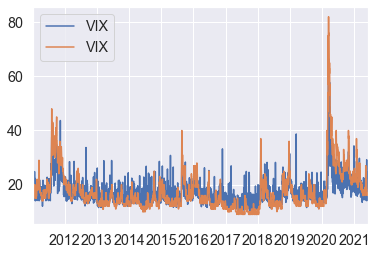

In [137]:
#predictions_df.plot() 
#test['VIX'].plot()

predictions_plot = predictions_df.plot()

fig = y_test.plot(ax = predictions_plot).get_figure()
fig.savefig("/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/images/random_forest_without_smoothing_sp500.png")
#matplotlib.pyplot.savefig("C:\Users\Farid\Documents\Project Options predictions\graphs\random forest without smoothing.png")

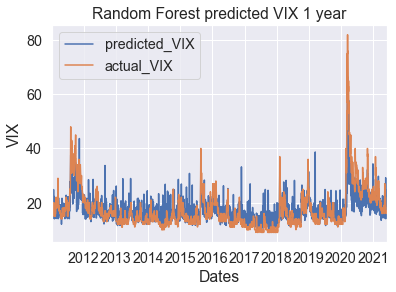

In [138]:
ax = predictions_df.rename(columns={"VIX": "predicted_VIX"}).plot(title='Random Forest predicted VIX 1 year')
ax.set_xlabel("Dates")
ax.set_ylabel("VIX")
fig = y_test.rename(columns={"VIX": "actual_VIX"}).plot(ax = ax).get_figure()
fig.savefig("/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/images/random_forest_without_smoothing2_sp500.png")

# colors = ['332288', '88CCEE', '44AA99', '117733', '999933', 'DDCC77', 'CC6677', '882255', 'AA4499']

In [139]:
test

,VIX,compound,neg,neu,pos,ForGraph,sentiment
2011-01-04,17,-0.9992,0.18,0.71,0.109,37.716263,37.716263
2011-01-05,17,-0.9925,0.183,0.731,0.086,31.970260,34.699612
2011-01-06,17,-0.9956,0.211,0.711,0.078,26.989619,31.868549
2011-01-07,17,-0.989,0.162,0.722,0.115,41.516245,34.653690
2011-01-08,17,-0.9963,0.199,0.684,0.117,37.025316,35.227366
...,...,...,...,...,...,...,...
2021-05-28,16,-0.9275,0.109,0.8,0.092,45.771144,38.278432
2021-05-29,17,-0.9897,0.142,0.81,0.048,25.263158,37.038882
2021-05-30,17,-0.9934,0.166,0.804,0.03,15.306122,34.969096
2021-05-31,17,-0.5139,0.104,0.795,0.1,49.019608,36.307240


In [140]:
# Increasing the VIX by a constant value so that it represents closing VIX during the testing

In [141]:
from datetime import datetime, timedelta

temp_date = test_start_date
print(test_start_date)
print(datetime.astimezone)
average_last_5_days_test = 0
total_days = 10
for i in range(total_days):
    average_last_5_days_test += test.loc[temp_date, 'VIX']
    # Converting string to date time
    temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
    # Reducing one day from date time
    difference = temp_date + timedelta(days=1)
    # Converting again date time to string
    temp_date = difference.strftime('%Y-%m-%d')
    #print temp_date
average_last_5_days_test = average_last_5_days_test / total_days
print (average_last_5_days_test)

temp_date = test_start_date
average_upcoming_5_days_predicted = 0
for i in range(total_days):
    average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
    # Converting string to date time
    temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
    # Adding one day from date time
    difference = temp_date + timedelta(days=1)
    # Converting again date time to string
    temp_date = difference.strftime('%Y-%m-%d')
    print(temp_date)
average_upcoming_5_days_predicted = average_upcoming_5_days_predicted / total_days
print (average_upcoming_5_days_predicted)
#average train.loc['2013-12-31', 'VIX'] - advpredictions_df.loc['2014-01-01', 'VIX']
difference_test_predicted_VIX = average_last_5_days_test - average_upcoming_5_days_predicted
print (difference_test_predicted_VIX)

2011-01-04
<method 'astimezone' of 'datetime.datetime' objects>
16.7
2011-01-05
2011-01-06
2011-01-07
2011-01-08
2011-01-09
2011-01-10
2011-01-11
2011-01-12
2011-01-13
2011-01-14
16.8479
-0.14789999999999992


In [142]:
predictions_df

,VIX
2011-01-04,16.770000
2011-01-05,17.120500
2011-01-06,15.675000
2011-01-07,15.620000
2011-01-08,14.490000
...,...
2021-05-28,19.118667
2021-05-29,16.635000
2021-05-30,16.270000
2021-05-31,24.670667


In [143]:
# Adding 6177 to all the advpredictions_df VIX values
predictions_df['VIX'] = predictions_df['VIX'] + difference_test_predicted_VIX
predictions_df

,VIX
2011-01-04,16.622100
2011-01-05,16.972600
2011-01-06,15.527100
2011-01-07,15.472100
2011-01-08,14.342100
...,...
2021-05-28,18.970767
2021-05-29,16.487100
2021-05-30,16.122100
2021-05-31,24.522767


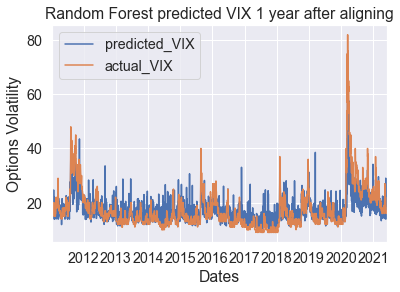

In [144]:
ax = predictions_df.rename(columns={"VIX": "predicted_VIX"}).plot(title='Random Forest predicted VIX 1 year after aligning')
ax.set_xlabel("Dates")
ax.set_ylabel("Options Volatility")
fig = y_test.rename(columns={"VIX": "actual_VIX"}).plot(ax = ax).get_figure()
fig.savefig("/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/images/random_forest_with_aligning_sp500.png")



# Smoothing the time series data

# Applying EWM pandas to smooth the VIX volatility

In [145]:
predictions_df

,VIX
2011-01-04,16.622100
2011-01-05,16.972600
2011-01-06,15.527100
2011-01-07,15.472100
2011-01-08,14.342100
...,...
2021-05-28,18.970767
2021-05-29,16.487100
2021-05-30,16.122100
2021-05-31,24.522767


In [146]:
predictions_df['ewm'] = predictions_df["VIX"].ewm(span=60).mean()

In [147]:
predictions_df

,VIX,ewm
2011-01-04,16.622100,16.622100
2011-01-05,16.972600,16.800271
2011-01-06,15.527100,16.361657
2011-01-07,15.472100,16.128027
2011-01-08,14.342100,15.746639
...,...,...
2021-05-28,18.970767,18.520170
2021-05-29,16.487100,18.453512
2021-05-30,16.122100,18.377072
2021-05-31,24.522767,18.578570


In [148]:
predictions_df['actual_value'] = test['VIX']
predictions_df['actual_value_ewm'] = predictions_df["actual_value"].ewm(span=60).mean()

In [149]:
predictions_df

,VIX,ewm,actual_value,actual_value_ewm
2011-01-04,16.622100,16.622100,17,17.000000
2011-01-05,16.972600,16.800271,17,17.000000
2011-01-06,15.527100,16.361657,17,17.000000
2011-01-07,15.472100,16.128027,17,17.000000
2011-01-08,14.342100,15.746639,17,17.000000
...,...,...,...,...
2021-05-28,18.970767,18.520170,16,18.754546
2021-05-29,16.487100,18.453512,17,18.697020
2021-05-30,16.122100,18.377072,17,18.641380
2021-05-31,24.522767,18.578570,17,18.587565


In [150]:
# Changing column names
predictions_df.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']

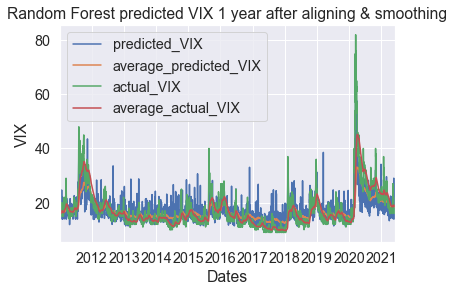

In [151]:
# Now plotting test predictions after smoothing
predictions_plot = predictions_df.plot(title='Random Forest predicted VIX 1 year after aligning & smoothing')
predictions_plot.set_xlabel("Dates")
predictions_plot.set_ylabel("VIX")
fig = predictions_plot.get_figure()
fig.savefig("/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/images/random_forest_after_smoothing_var_sp500.png")


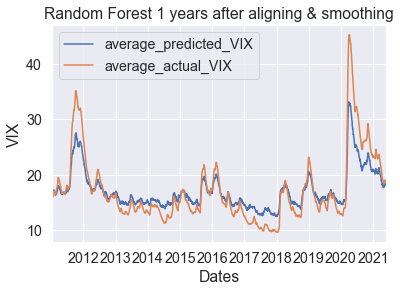

In [152]:
# Plotting just predict and actual average curves
predictions_df_average = predictions_df[['average_predicted_VIX', 'average_actual_VIX']]
predictions_plot = predictions_df_average.plot(title='Random Forest 1 years after aligning & smoothing')
predictions_plot.set_xlabel("Dates")
predictions_plot.set_ylabel("VIX")
fig = predictions_plot.get_figure()
fig.savefig("/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/images/random_forest_after_smoothing2_mean_sp500.png")

# Increasing the VIX by a constant value so that it represents closing VIX during the testing

In [153]:
def offset_value(test_start_date, test, predictions_df):
    temp_date = test_start_date
    average_last_5_days_test = 0
    average_upcoming_5_days_predicted = 0
    total_days = 10
    for i in range(total_days):
        average_last_5_days_test += test.loc[temp_date, 'VIX']
        temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
        difference = temp_date + timedelta(days=1)
        temp_date = difference.strftime('%Y-%m-%d')
    average_last_5_days_test = average_last_5_days_test / total_days

    temp_date = test_start_date
    for i in range(total_days):
        average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
        temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
        difference = temp_date + timedelta(days=1)
        temp_date = difference.strftime('%Y-%m-%d')
    average_upcoming_5_days_predicted = average_upcoming_5_days_predicted / total_days
    difference_test_predicted_VIX = average_last_5_days_test - average_upcoming_5_days_predicted
    return difference_test_predicted_VIX

# LogisticRegression

#1
121784
192984
####################### 1 ######################
2011-01-04    17
2011-01-05    17
2011-01-06    17
2011-01-07    17
2011-01-08    17
              ..
2021-05-28    16
2021-05-29    17
2021-05-30    17
2021-05-31    17
2021-06-01    17
Freq: D, Name: VIX, Length: 3802, dtype: int64
######################## 2 #####################
[[-0.9992  0.18    0.71    0.109 ]
 [-0.9925  0.183   0.731   0.086 ]
 [-0.9956  0.211   0.711   0.078 ]
 ...
 [-0.9934  0.166   0.804   0.03  ]
 [-0.5139  0.104   0.795   0.1   ]
 [-0.9977  0.16    0.78    0.06  ]]
######################## 3 #####################
#6
2011-01-04 2021-06-01 2011-01-04 2021-06-01
#7


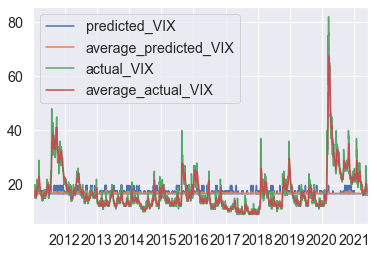

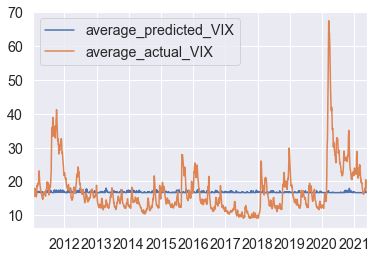

In [154]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from datetime import datetime, timedelta

# average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
# # Converting string to date time
# temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
# # Adding one day from date time
# difference = temp_date + timedelta(days=1)
# # Converting again date time to string
# temp_date = difference.strftime('%Y-%m-%d')
        
# start_year = datetime.strptime(train_start_date, "%Y-%m-%d").date().month

prediction_list = []

# Splitting the training and testing data
train_start_date = '2011-01-04'
train_end_date = '2021-06-01'
test_start_date = '2011-01-04'
test_end_date = '2021-06-01'
train = df.loc[train_start_date : train_end_date]
test = df.loc[test_start_date : test_end_date]

# Calculating the sentiment score
sentiment_score_list = []
for date, row in train.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)
sentiment_score_list = []
print("#1")
for date, row in test.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)
# Generating models
# Linear regression model
lr = LogisticRegression()
print(sys.getsizeof(numpy_df_train))
print(sys.getsizeof(train['VIX']))

print("####################### 1 ######################")
print(train['VIX'])
print("######################## 2 #####################")
print(numpy_df_train)
print("######################## 3 #####################")
lr.fit(numpy_df_train, train['VIX'])

#   if len(np.sum(train['VIX'])) in [len(train['VIX']),0]:
#       print ("all one class")
#       #do something else
#   else:
#       #OK to proceed
#       lenreg.fit(numpy_df_train, train['VIX'])
#       y_pred = lenreg.predict(numpy_df_train)
#       print (metics.accuracy_score(y_test, y_pred))


print("#6")

prediction = lr.predict(numpy_df_test)
prediction_list.append(prediction)
print (train_start_date + ' ' + train_end_date + ' ' + test_start_date + ' ' + test_end_date)
idx = pd.date_range(test_start_date, test_end_date)
#print year
predictions_df_list = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])

difference_test_predicted_VIX = offset_value(test_start_date, test, predictions_df_list)
# Adding offset to all the advpredictions_df VIX values
predictions_df_list['VIX'] = predictions_df_list['VIX'] + difference_test_predicted_VIX
predictions_df_list

# Smoothing the plot
predictions_df_list['ewm'] = predictions_df_list["VIX"].ewm(span=10).mean()
predictions_df_list['actual_value'] = test['VIX']
predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=10).mean()
# Changing column names
predictions_df_list.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']
predictions_df_list.plot()
predictions_df_list_average = predictions_df_list[['average_predicted_VIX', 'average_actual_VIX']]
predictions_df_list_average.plot()
print("#7")
#     predictions_df_list.show()


In [155]:
lr.classes_

array([ 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25,
       26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42,
       43, 44, 45, 46, 47, 48, 50, 53, 54, 57, 59, 61, 62, 63, 64, 65, 66,
       72, 74, 75, 76, 82], dtype=int64)

In [156]:
lr.coef_[0]

array([-0.45558883,  0.67625626, -0.52157697, -0.11733227])

# RandomForestRegressor

<AxesSubplot:>

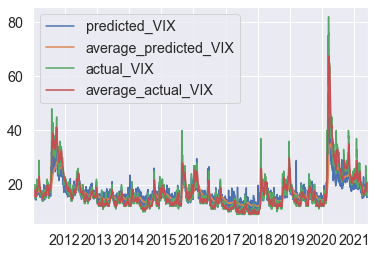

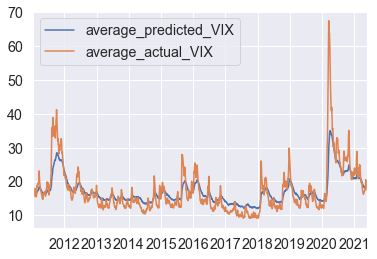

In [157]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from datetime import datetime, timedelta

# average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
# # Converting string to date time
# temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
# # Adding one day from date time
# difference = temp_date + timedelta(days=1)
# # Converting again date time to string
# temp_date = difference.strftime('%Y-%m-%d')
        
# start_year = datetime.strptime(train_start_date, "%Y-%m-%d").date().month

prediction_list = []
# Splitting the training and testing data
train_start_date = '2011-01-04'
train_end_date = '2021-06-01'
test_start_date = '2011-01-04'
test_end_date = '2021-06-01'
train = df.loc[train_start_date : train_end_date]
test = df.loc[test_start_date:test_end_date]

# Calculating the sentiment score
sentiment_score_list = []
for date, row in train.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)
sentiment_score_list = []
for date, row in test.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)
# Generating models
rf = RandomForestRegressor(random_state=0)
rf.fit(numpy_df_train, train['VIX'])
#print rf

prediction, bias, contributions = ti.predict(rf, numpy_df_test)
prediction_list.append(prediction)
#print train_start_date + ' ' + train_end_date + ' ' + test_start_date + ' ' + test_end_date
idx = pd.date_range(test_start_date, test_end_date)
#print year
predictions_df_list = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])

difference_test_predicted_VIX = offset_value(test_start_date, test, predictions_df_list)
# Adding offset to all the advpredictions_df VIX values
predictions_df_list['VIX'] = predictions_df_list['VIX'] + difference_test_predicted_VIX
predictions_df_list

# Smoothing the plot
predictions_df_list['ewm'] = predictions_df_list["VIX"].ewm(span=60).mean()
predictions_df_list['actual_value'] = test['VIX']
predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=10).mean()
# Changing column names
predictions_df_list.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']
predictions_df_list.plot()
predictions_df_list_average = predictions_df_list[['average_predicted_VIX', 'average_actual_VIX']]
predictions_df_list_average.plot()

#     predictions_df_list.show()


In [158]:
# from IPython.display import Image  
# dot_data = tree.export_graphviz(rf, out_file=None, 
#                      feature_names=['comp', 'neg', 'neu', 'pos'],  
#                      class_names=iris.target_names,  
#                      filled=True, rounded=True,  
#                      special_characters=True)  
# graph = pydotplus.graph_from_dot_data(dot_data)  
# Image(graph.create_png())

# MLP Classifier

<AxesSubplot:>

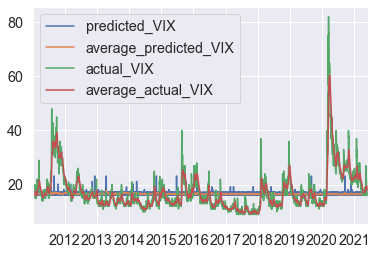

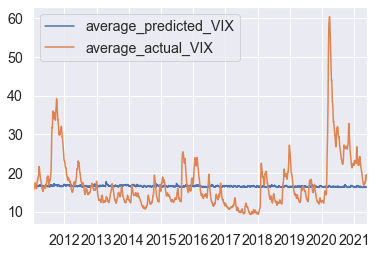

In [159]:
from sklearn.neural_network import MLPClassifier
from datetime import datetime, timedelta

# average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
# # Converting string to date time
# temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
# # Adding one day from date time
# difference = temp_date + timedelta(days=1)
# # Converting again date time to string
# temp_date = difference.strftime('%Y-%m-%d')
        
# start_year = datetime.strptime(train_start_date, "%Y-%m-%d").date().month

prediction_list = []
# Splitting the training and testing data
train_start_date = '2011-01-04'
train_end_date = '2021-06-01'
test_start_date = '2011-01-04'
test_end_date = '2021-06-01'
train = df.loc[train_start_date : train_end_date]
test = df.loc[test_start_date:test_end_date]

# Calculating the sentiment score
sentiment_score_list = []
for date, row in train.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)
sentiment_score_list = []
for date, row in test.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)

# Generating models
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='relu', 
                        solver='lbfgs', alpha=0.005, learning_rate_init = 0.001, shuffle=False) # span = 20 # best 1
mlpc.fit(numpy_df_train, train['VIX'])   
prediction = mlpc.predict(numpy_df_test)

prediction_list.append(prediction)
#print train_start_date + ' ' + train_end_date + ' ' + test_start_date + ' ' + test_end_date
idx = pd.date_range(test_start_date, test_end_date)
#print year
predictions_df_list = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])

difference_test_predicted_VIX = offset_value(test_start_date, test, predictions_df_list)
# Adding offset to all the advpredictions_df VIX values
predictions_df_list['VIX'] = predictions_df_list['VIX'] + difference_test_predicted_VIX
predictions_df_list

# Smoothing the plot
predictions_df_list['ewm'] = predictions_df_list["VIX"].ewm(span=20).mean()
predictions_df_list['actual_value'] = test['VIX']
predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=20).mean()
# Changing column names
predictions_df_list.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']
predictions_df_list.plot()
predictions_df_list_average = predictions_df_list[['average_predicted_VIX', 'average_actual_VIX']]
predictions_df_list_average.plot()

#     predictions_df_list.show()
    

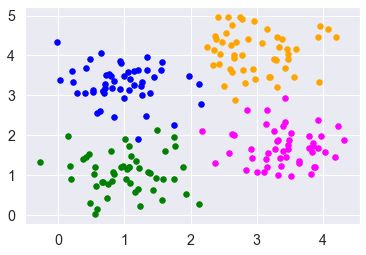

In [160]:

#my addition
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

n_samples = 200
blob_centers = ([1, 1], [3, 4], [1, 3.3], [3.5, 1.8])
data, labels = make_blobs(n_samples=n_samples, 
                          centers=blob_centers, 
                          cluster_std=0.5,
                          random_state=0)


colours = ('green', 'orange', "blue", "magenta")
fig, ax = plt.subplots()

for n_class in range(len(blob_centers)):
    ax.scatter(data[labels==n_class][:, 0], 
               data[labels==n_class][:, 1], 
               c=colours[n_class], 
               s=30, 
               label=str(n_class))

In [163]:
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='tanh', 
                         solver='lbfgs', alpha=0.010, learning_rate_init = 0.001, shuffle=False)
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='relu', 
                         solver='lbfgs', alpha=0.010, learning_rate_init = 0.001, shuffle=False) # span = 20
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='relu', 
                         solver='lbfgs', alpha=0.005, learning_rate_init = 0.001, shuffle=False) # span = 20 # best 1
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 50), activation='relu', 
                         solver='lbfgs', alpha=0.005, learning_rate_init = 0.001, shuffle=False)
                     

<AxesSubplot:>

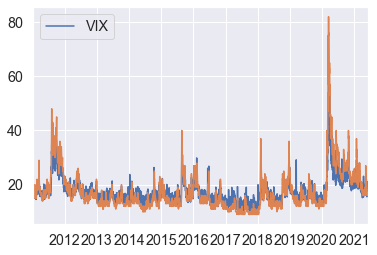

In [162]:
# checking the performance of training data itself
prediction, bias, contributions = ti.predict(rf, numpy_df_train)
idx = pd.date_range(train_start_date, train_end_date)
predictions_df1 = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])
predictions_df1.plot()
train['VIX'].plot()